In [706]:
from sklearn.cluster import KMeans
import numpy as np
import matplotlib.pyplot as plt

import numpy as np
import joblib
import importlib
import matplotlib.pyplot as plt
import os 
import pickle
import bayes_logistic as bl
from collections import defaultdict
import warnings
warnings.filterwarnings("ignore")
from tqdm import trange, tqdm
import math

os.chdir('/Users/eochoa/Documents/Research_Ambuj/ASD/Code/')

import pandas as pd
from utils import *
#from linear_utils import *
from logistic_utils import *
from GP_utils import *
from linear_utils import *
import expt_utils as expt_utils
from sklearn.preprocessing import normalize
from sklearn.datasets import load_iris
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.mixture import GaussianMixture
from sklearn.mixture import BayesianGaussianMixture
from scipy.special import expit, logit
import sklearn
import seaborn as sns
# importlib.reload(expt_utils)
from sklearn.neighbors import NearestNeighbors

from sklearn.metrics import pairwise_distances

from scipy.stats import multivariate_normal

In [707]:
expit = lambda x: 1/(1+np.exp(-x))
def gen_data(N=100, p=2, scale=1):

    #N = 10000
    #p = 10
    theta = scale*(2*np.random.rand(p)-1)
    r = np.random.rand(N).reshape(N, 1)-1
    x = np.random.rand(N,p).reshape(N, p)
    x = x - x.mean(0)
    x = r*normalize(x, axis=1, norm='l2')
    
    #x = np.random.rand(p*N).reshape(N, p)
    
    x_ = np.concatenate([np.ones((N,1)), x],axis=1)
    f = x @ theta
    #f = np.power(f,2)
    p = expit(f)
    y = np.random.binomial(1,p)
    return x, y, theta

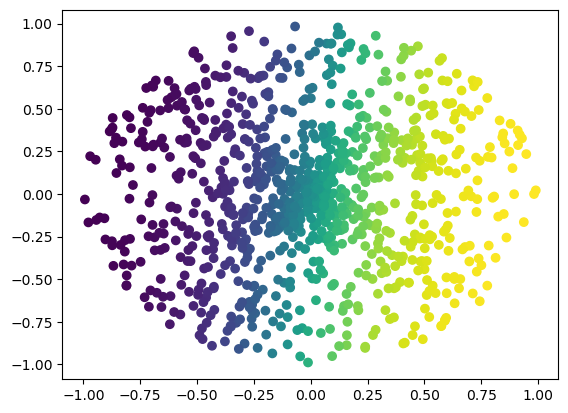

In [708]:
x, y, theta = gen_data(1000, scale=10)
plt.scatter(x[:,0],x[:,1], c=expit(x @ theta))

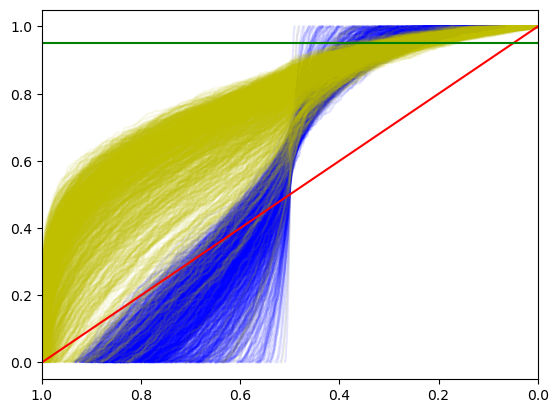

In [709]:
for i in range(1000):
    x, y, theta = gen_data(1000, scale=2)
    plt.plot(np.sort(expit(x @ theta))[::-1],
             y[np.argsort(expit(x @ theta))[::-1]].cumsum()/y.sum(), c='b', alpha=.1)
    plt.xlim(1,0)
    
for i in range(1000):
    x, y, theta = gen_data(1000, scale=10)
    plt.plot(np.sort(expit(x @ theta))[::-1],
             y[np.argsort(expit(x @ theta))[::-1]].cumsum()/y.sum(), c='y', alpha=.1)
    plt.xlim(1,0)
    
    
plt.plot(np.linspace(0,1,100),
         np.linspace(1,0,100),c='r')

plt.plot(np.linspace(0,1,100),
         .95*np.ones(100),c='g')

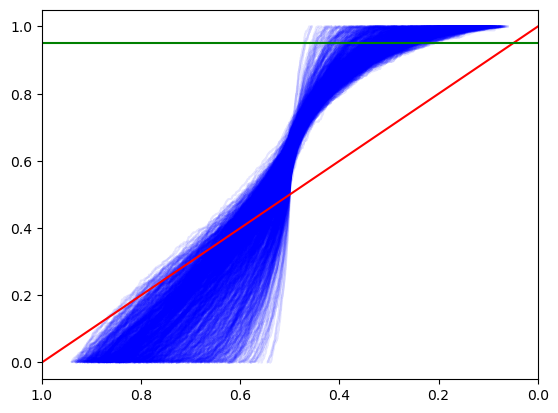

In [710]:
for i in range(1000):
    x, y, theta = gen_data(1000, scale=2)
    plt.plot(np.sort(expit(x @ theta))[::-1],
             y[np.argsort(expit(x @ theta))[::-1]].cumsum()/y.sum(), c='b', alpha=.1)
    plt.xlim(1,0)
    
plt.plot(np.linspace(0,1,100),
         np.linspace(1,0,100),c='r')

plt.plot(np.linspace(0,1,100),
         .95*np.ones(100),c='g')

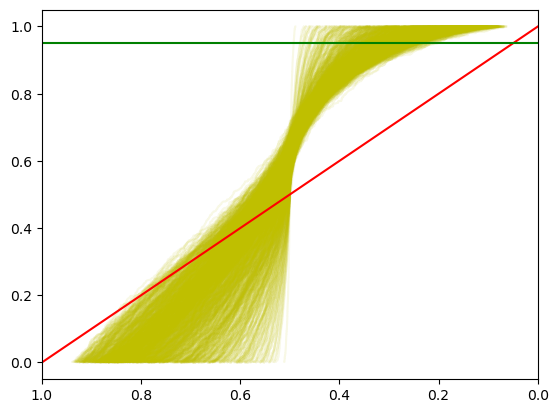

In [711]:
tau_list = []
prob_list = []
for i in range(1000):
    x, y, theta = gen_data(1000, scale=2)
    tau_list.append(((y[np.argsort(expit(x @ theta))[::-1]].cumsum()/y.sum() > 0.95).cumsum() == 0).sum())
    prob_list.append(np.sort(expit(x @ theta))[::-1][((y[np.argsort(expit(x @ theta))[::-1]].cumsum()/y.sum() > 0.95).cumsum() == 0).sum()])
    
    plt.plot(np.sort(expit(x @ theta))[::-1],
             y[np.argsort(expit(x @ theta))[::-1]].cumsum()/y.sum(), c='y', alpha=.1)
    plt.xlim(1,0)
    
    
plt.plot(np.linspace(0,1,100),
         np.linspace(1,0,100),c='r')

plt.plot(np.linspace(0,1,100),
         .95*np.ones(100),c='g')
    

(array([  4.,  16.,  51., 104., 135., 222., 195., 157.,  96.,  20.]),
 array([806. , 821.6, 837.2, 852.8, 868.4, 884. , 899.6, 915.2, 930.8,
        946.4, 962. ]),
 <BarContainer object of 10 artists>)

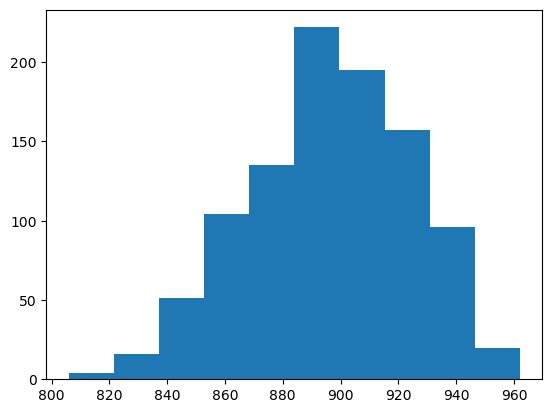

In [712]:
plt.hist(tau_list)

100%|███████████████████████████████████████████| 30/30 [00:09<00:00,  3.05it/s]


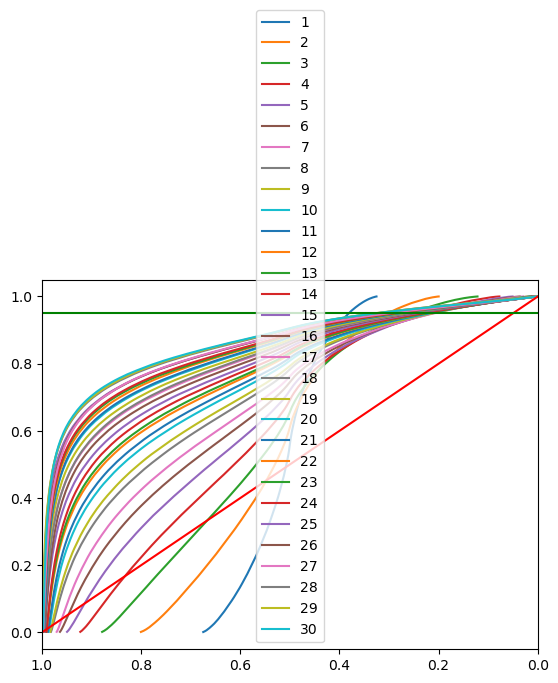

In [713]:
taus = []
probs = []
for j in trange(1,31):
    
    x_=[]
    y_=[]
    for i in range(1000):
        x, y, theta = gen_data(1000, scale=j)
        x_.append(np.sort(expit(x @ theta))[::-1])
        y_.append(y[np.argsort(expit(x @ theta))[::-1]].cumsum()/y.sum())
    
    taus.append(np.where((np.mean(y_,0)>.9).cumsum() ==1)[0][0])
    probs.append(np.mean(x_,0)[np.where((np.mean(y_,0)>.9).cumsum() ==1)][0])
    plt.plot(np.mean(x_,0),
            np.mean(y_,0), label=str(j))



plt.xlim(1,0)
plt.legend()
    
plt.plot(np.linspace(0,1,100),
         np.linspace(1,0,100),c='r')

plt.plot(np.linspace(0,1,100),
         .95*np.ones(100),c='g')

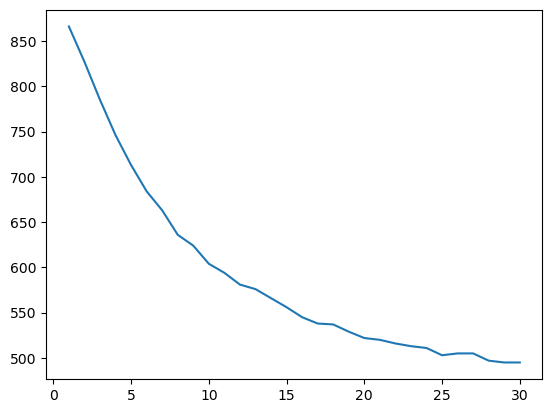

In [714]:
plt.plot(range(1,len(taus)+1),taus)

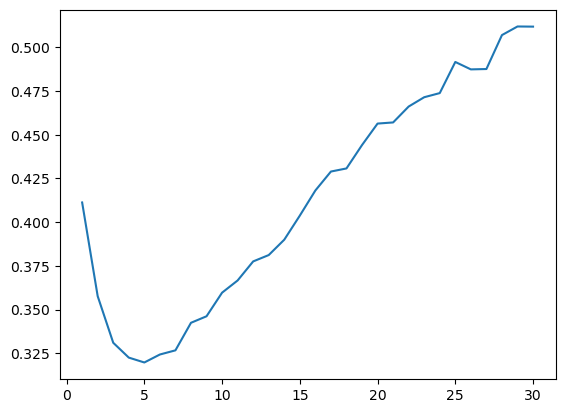

In [715]:
plt.plot(range(1,len(taus)+1),probs)

In [716]:
algos_dict = {
    'IDS_logistic': [IDS_logistic, {'prob_threshold':.3}, 10, 'IDS_logistic', 'y'],
    'Greedy_logistic': [G_logistic, {'prob_threshold':.3}, 10, 'Greedy_logistic', 'green'],
    'TS_logistic': [TS_logistic, {'prob_threshold':.3}, 10, 'TS_logistic', 'red'],
    #'Greedy_logistic_2': [G_logistic, {'n_clus':50, 'ss_size':5, 'optimal_marg':.5}, 1, 'Greedy_logistic_2', 'green']
}

In [740]:
#res_G = defaultdict(list)

reg_list = {algo:[] for algo in algos_dict}
rwd_ev_list = {algo:[] for algo in algos_dict}
rwd_list = {algo:[] for algo in algos_dict}
rwd_prop_list = {algo:[] for algo in algos_dict}
tau_list = {algo:[] for algo in algos_dict}
tau_true_list = {algo:[] for algo in algos_dict}
sample_list = {var:[] for var in ['x', 'y', 'theta', 'true_tau']}

for trial_idx in trange(10):
    x, y, theta = gen_data(100, scale=10)
    n_row, n_col = y.shape[0], 1
    _, n_desc =  x.shape
    cutoff = n_desc
    T = n_row
    prob_dict = {
                "m": n_row,
                "noise": 0.01,
                "d": cutoff
              }
    prob = logistic_discover(**prob_dict)
    #x = x - x.mean(0)
    #x = normalize(x, axis=0, norm='l2')
    prob.x = x.copy()
    prob.y = y.copy()
    #t_prob = deepcopy(prob)
    #solver = G_logistic(t_prob, prob_threshold=0.25) 
        #reg, act = solver.run(T, refresh=False)[:2]

        #actions_0 = [np.random.choice(np.arange(1000)[kmeans.labels_ == c]) for c in range(10)]

    #reg, rwd, tau = solver.run(T)
    
    #res_G['true_tau'].append(((y[np.argsort(expit(x @ theta))[::-1]].cumsum()/y.sum() > 0.95).cumsum() == 0).sum())
    #res_G['reg'].append(reg)
    #res_G['tau'].append(tau)
    #res_G['rwd_prop'].append(np.array(rwd).sum()/y.sum())
    
    sample_list['x'].append(x)
    sample_list['y'].append(y)
    sample_list['true_tau'].append(((y[np.argsort(expit(x @ theta))[::-1]].cumsum()/y.sum() > 0.95).cumsum() == 0).sum())
    
    sample_list['theta'].append(theta)
    
    for algo, algo_setup in algos_dict.items():
        t_prob = deepcopy(prob)
        algo_func, algo_params, algo_N_trials, _, _ = algo_setup
                        # print(algo_func)
        if not trial_idx < algo_N_trials:
            continue
        solver = algo_func(t_prob, **algo_params)
        reg, rwd, tau = solver.run(T,M=0.95*y.sum())#[:2]
                #act_list[algo].append(getattr(solver, "logistic_discover"))
                #act_list[algo].append(t_prob.actions)
                # print(prob.rewards)
        if np.isnan(tau):
            tau = T
        reg_list[algo].append(reg)
        rwd_list[algo].append(rwd)
        rwd_ev_list[algo].append(t_prob.rewards_ev)
        tau_true_list[algo].append(t_prob.tau_true)
        tau_list[algo].append(tau)
        rwd_prop_list[algo].append(np.array(rwd)[:tau].sum()/y.sum())
        

100%|███████████████████████████████████████████| 10/10 [00:12<00:00,  1.24s/it]


# Include uncert in TS and IDS

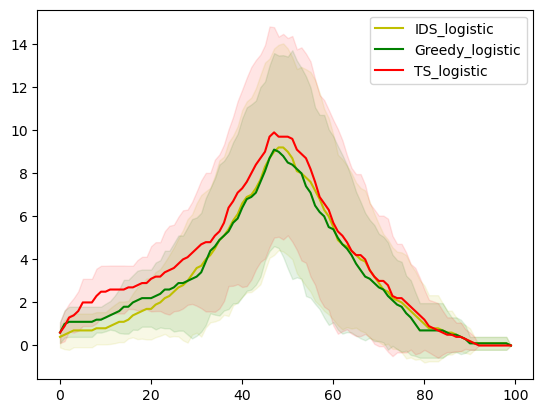

In [741]:
alpha = 0
for algo in algos_dict:
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    y_ = np.mean(reg_list[algo], axis = 0)[:1000]
    y_ = y_ / np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    ci = np.std(reg_list[algo], axis = 0)[:1000]/ np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    plt.plot(range(y_.shape[0]), y_,
                  algo_style, label=algo_label)
    plt.fill_between(range(y_.shape[0]), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

    plt.legend()

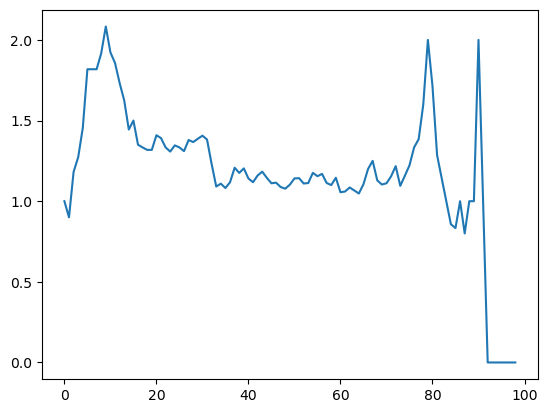

In [742]:
plt.plot(np.mean(reg_list['TS_logistic'], axis = 0) / np.mean(reg_list['Greedy_logistic'], axis = 0))

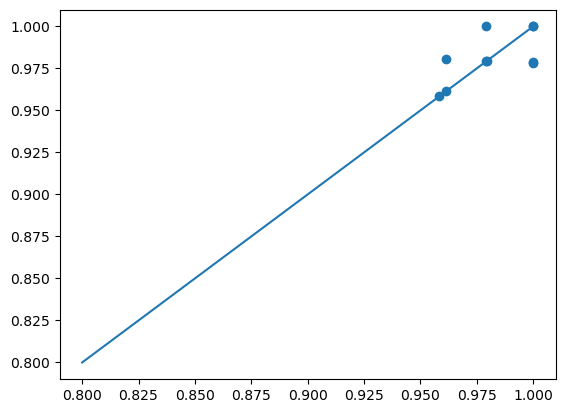

In [743]:
plt.scatter(rwd_prop_list['Greedy_logistic'],
rwd_prop_list['TS_logistic'])
plt.plot(np.linspace(.8,1),
        np.linspace(.8,1))

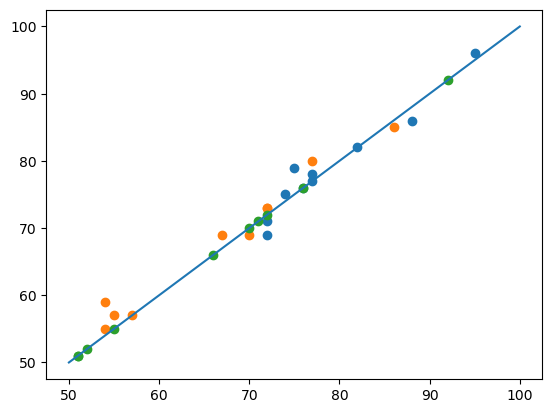

In [744]:
plt.scatter(tau_list['Greedy_logistic'],
            tau_list['TS_logistic'])

plt.plot(np.linspace(50,100),
        np.linspace(50,100))

plt.scatter(tau_true_list['Greedy_logistic'],
            tau_true_list['TS_logistic'])

plt.scatter(sample_list['true_tau'],
           sample_list['true_tau'])

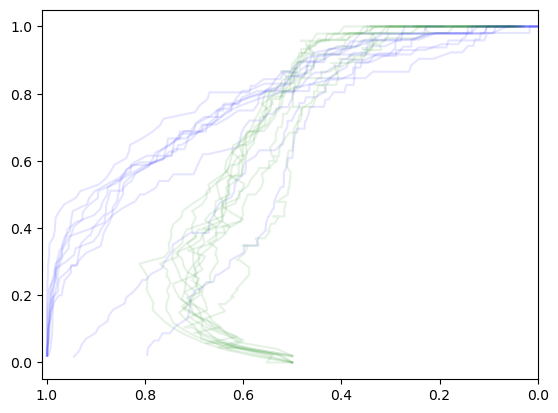

In [724]:
for i in range(10):
    probs = expit(sample_list['x'][i] @ sample_list['theta'][i])
    y = sample_list['y'][i]
    plt.plot(np.sort(probs)[::-1],
             y[np.argsort(probs)[::-1]].cumsum()/y.sum(),
             alpha=.1, c='b')

    plt.plot(rwd_ev_list['Greedy_logistic'][i],
             np.cumsum(rwd_list['Greedy_logistic'][i])/y.sum(), 
             alpha=.1, c='g', label='greedy')

    #plt.plot(rwd_ev_list['TS_logistic'][i],
    #         np.cumsum(rwd_list['TS_logistic'][i])/y.sum(), 
    #         alpha=.1, c='r', label='TS')
    plt.xlim(1.01,0)
#plt.legend()

(1.01, 0.0)

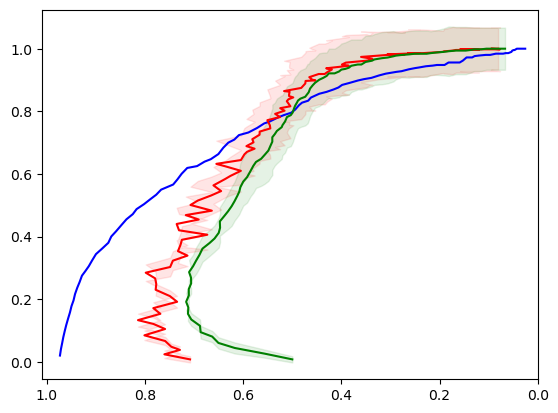

In [725]:
#probs = expit(sample_list['x'][i] @ sample_list['theta'][i])
#y = sample_list['y'][i]

#plt.plot(np.sort(probs)[::-1],
#             y[np.argsort(probs)[::-1]].cumsum()/y.sum(),
#             alpha=.1, c='b')
    
probs = [expit(x @ theta) for x, theta in zip(sample_list['x'], sample_list['theta'])]
y = [y for y in sample_list['y']]

plt.plot(np.mean([np.sort(p)[::-1] for p in probs], 0),
         np.mean([y[np.argsort(p)[::-1]].cumsum()/y.sum() for y, p in zip(sample_list['y'], probs)], 0), c='b')

plt.plot(np.mean(rwd_ev_list['TS_logistic'],0),
          np.mean(np.cumsum(rwd_list['TS_logistic'],1),0) / np.sum(sample_list['y'],1).mean(),
             alpha=1, c='r', label='TS')

z_ = np.mean(np.cumsum(rwd_list['TS_logistic'],1),0) / np.sum(sample_list['y'],1).mean()
di = np.std(np.cumsum(rwd_list['TS_logistic'],1),0) / np.sum(sample_list['y'],1).mean()

plt.fill_between(np.mean(rwd_ev_list['TS_logistic'],0).flatten(), (z_-di), (z_+di), color = 'r', alpha=.1)


plt.plot(np.mean(rwd_ev_list['Greedy_logistic'],0),
          np.mean(np.cumsum(rwd_list['Greedy_logistic'],1),0) / np.sum(sample_list['y'],1).mean(),
             alpha=1, c='g', label='greedy')

y_ = np.mean(np.cumsum(rwd_list['Greedy_logistic'],1),0) / np.sum(sample_list['y'],1).mean()
ci = np.std(np.cumsum(rwd_list['Greedy_logistic'],1),0) / np.sum(sample_list['y'],1).mean()

plt.fill_between(np.mean(rwd_ev_list['Greedy_logistic'],0), (y_-ci), (y_+ci), color = 'g', alpha=.1)

plt.xlim(1.01,0)

In [747]:
solver.prob.actions

[44,
 92,
 38,
 9,
 83,
 22,
 23,
 98,
 87,
 95,
 79,
 53,
 11,
 39,
 8,
 52,
 42,
 82,
 17,
 63,
 66,
 37,
 5,
 3,
 33,
 36,
 25,
 99,
 41,
 0,
 85,
 18,
 28,
 47,
 50,
 77,
 90,
 26,
 40,
 86,
 54,
 14,
 72,
 58,
 75,
 61,
 81,
 88,
 91,
 93,
 73,
 29,
 94,
 45,
 69,
 78,
 6,
 31,
 60,
 12,
 64,
 19,
 59,
 67,
 24,
 56,
 43,
 68,
 74,
 1,
 97,
 35,
 65,
 34,
 55,
 16,
 49,
 30,
 46,
 20,
 76,
 27,
 2,
 21,
 71,
 10,
 62,
 13,
 48,
 57,
 89,
 32,
 51,
 80,
 96,
 7,
 15,
 84,
 70,
 4]

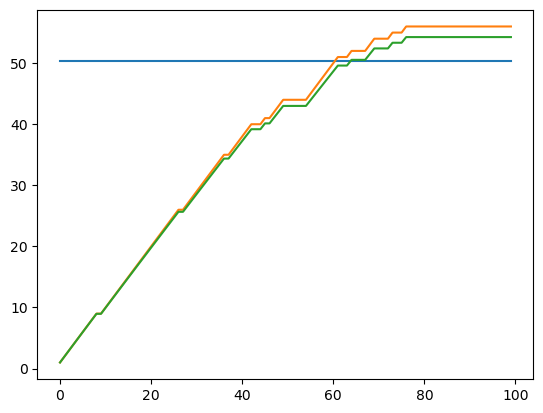

In [748]:
gamma = .999
disc = np.power(np.ones(100) * gamma, np.arange(100))

plt.plot(range(100), np.ones(100)*y[solver.prob.actions].sum()*.9)
plt.plot((y[solver.prob.actions]).cumsum())
plt.plot((y[solver.prob.actions] * disc).cumsum())

0.9043820750088044 76
0.9135172474836408 76
0.9227446944279201 76
0.9320653479069899 76
0.941480149401 76
0.9509900498999999 76
0.96059601 76
0.970299 76
0.9801 76
0.99 42


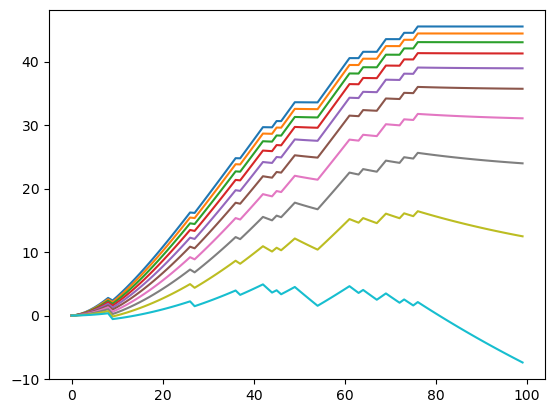

In [749]:
for gamma in np.logspace(10,1,base=.99, num=10): 
    disc = np.power(np.ones(100) * gamma, np.arange(100))
    print(gamma, np.argmax((y[solver.prob.actions]  - disc).cumsum()))
    plt.plot((y[solver.prob.actions]  - disc).cumsum())

In [766]:
ts = (np.argmax(np.clip((1.2*y[solver.prob.actions]-.2).cumsum(), 0,100)),
np.argmax(np.clip((1.5*y[solver.prob.actions]-.5).cumsum(), 0,100)),
np.argmax(np.clip((2*y[solver.prob.actions]-1).cumsum(), 0,100)),
np.argmax(np.clip((3*y[solver.prob.actions]-2).cumsum(), 0,100)),
np.argmax(np.clip((4*y[solver.prob.actions]-3).cumsum(), 0,100)),
np.argmax(np.clip((10*y[solver.prob.actions]-9).cumsum(), 0,100)))
ts

(76, 69, 61, 42, 42, 26)

In [765]:
[np.sum(y[solver.prob.actions[:t]])/np.sum(y[solver.prob.actions]) for t in ts]

[0.9821428571428571,
 0.9464285714285714,
 0.8928571428571429,
 0.6964285714285714,
 0.6964285714285714,
 0.44642857142857145]

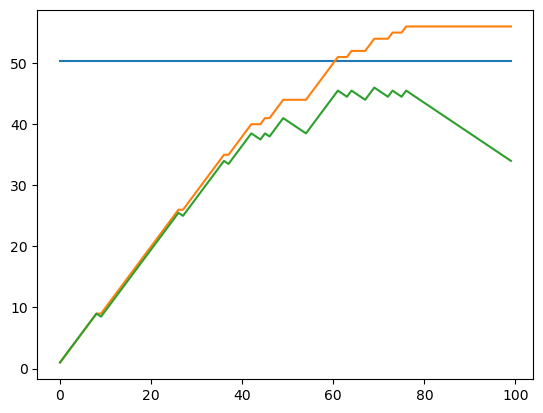

In [767]:
plt.plot(range(100), np.ones(100)*y[solver.prob.actions].sum()*.9)
plt.plot((y[solver.prob.actions]).cumsum())
#plt.plot(np.clip((1.2*y[solver.prob.actions]-.2).cumsum(), 0,100))
plt.plot(np.clip((1.5*y[solver.prob.actions]-.5).cumsum(), 0,100))
#plt.plot(np.clip((2*y[solver.prob.actions]-1).cumsum(), 0,100))
#plt.plot(np.clip((3*y[solver.prob.actions]-2).cumsum(), 0,100))
#plt.plot(np.clip((4*y[solver.prob.actions]-3).cumsum(), 0,100))

#plt.plot(np.clip((10*y[solver.prob.actions]-9).cumsum(), 0,100))

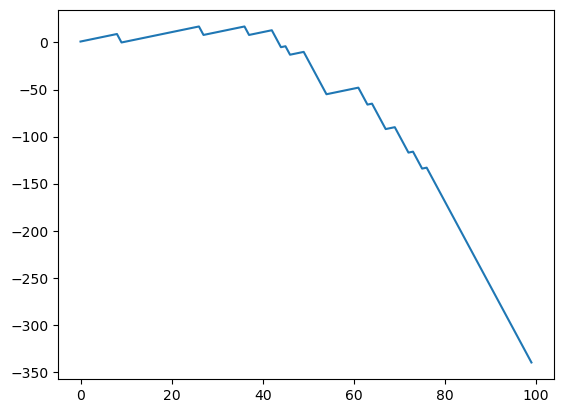

In [754]:
plt.plot((10*y[solver.prob.actions]-9).cumsum())
#plt.ylim(0,400)